# PREDICT SONG POPULARITY FROM AUDIO FEATURES

In [138]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso

## Loading the dataset and enlightening ourselves with the data structure.

In [83]:
music = pd.read_csv("https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv")

In [84]:
music.head() # First 5 Rows for obvious reasons which I am not aware about... hehe
music.describe() # For knowing the data well, and I mean well well...

,track_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000
mean,42.477081,0.654850,0.698619,5.374471,-6.719499,0.565711,0.107068,0.175334,0.084747,0.190176,0.510561,120.881132,225799.811622
std,24.984074,0.145085,0.180910,3.611657,2.988436,0.495671,0.101314,0.219633,0.224230,0.154317,0.233146,26.903624,59834.006182
min,0.000000,0.000000,0.000175,0.000000,-46.448000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4000.000000
25%,24.000000,0.563000,0.581000,2.000000,-8.171000,0.000000,0.041000,0.015100,0.000000,0.092700,0.331000,99.960000,187819.000000
50%,45.000000,0.672000,0.721000,6.000000,-6.166000,1.000000,0.062500,0.080400,0.000016,0.127000,0.512000,121.984000,216000.000000
75%,62.000000,0.761000,0.840000,9.000000,-4.645000,1.000000,0.132000,0.255000,0.004830,0.248000,0.693000,133.918000,253585.000000
max,100.000000,0.983000,1.000000,11.000000,1.275000,1.000000,0.918000,0.994000,0.994000,0.996000,0.991000,239.440000,517810.000000


In [85]:
music.shape # Tells us how many rows and columns. And yes it includes the index column... haha
music.dtypes # Shows the type of data present in each column (int64, str, float64)

track_id                        str
track_name                      str
track_artist                    str
track_popularity              int64
track_album_id                  str
track_album_name                str
track_album_release_date        str
playlist_name                   str
playlist_id                     str
playlist_genre                  str
playlist_subgenre               str
danceability                float64
energy                      float64
key                           int64
loudness                    float64
mode                          int64
speechiness                 float64
acousticness                float64
instrumentalness            float64
liveness                    float64
valence                     float64
tempo                       float64
duration_ms                   int64
dtype: object

In [86]:
(music.dtypes == 'float64').sum()

np.int64(9)

**Shape of the dataset is (32833, 23) including the index column** \
**Total of 10 string columns, 4 integer columns and 9 float columns**

In [87]:
music.isnull().sum() # Checks the amount of NULL data(empty data) present in each column

track_id                    0
track_name                  5
track_artist                5
track_popularity            0
track_album_id              0
track_album_name            5
track_album_release_date    0
playlist_name               0
playlist_id                 0
playlist_genre              0
playlist_subgenre           0
danceability                0
energy                      0
key                         0
loudness                    0
mode                        0
speechiness                 0
acousticness                0
instrumentalness            0
liveness                    0
valence                     0
tempo                       0
duration_ms                 0
dtype: int64

In [88]:
music.duplicated().sum() # Checking for duplicate values because why not. They mess up the dataset.
music.dropna(inplace = True) # We had very less (about negligible amount) NULL rows which were string anyways so dropping them made sense since it would cause a problem with training or testing data in the future. 
music.isnull().sum() # Just a check if its gone through.

track_id                    0
track_name                  0
track_artist                0
track_popularity            0
track_album_id              0
track_album_name            0
track_album_release_date    0
playlist_name               0
playlist_id                 0
playlist_genre              0
playlist_subgenre           0
danceability                0
energy                      0
key                         0
loudness                    0
mode                        0
speechiness                 0
acousticness                0
instrumentalness            0
liveness                    0
valence                     0
tempo                       0
duration_ms                 0
dtype: int64

**Plotting the graph to have a look of the data distribution and see what the skewness is all about. Here it is slightly left skewed because of the tail on the left side, SIMPLE! If the tail would have been on the right side, it would have been right skewed.**

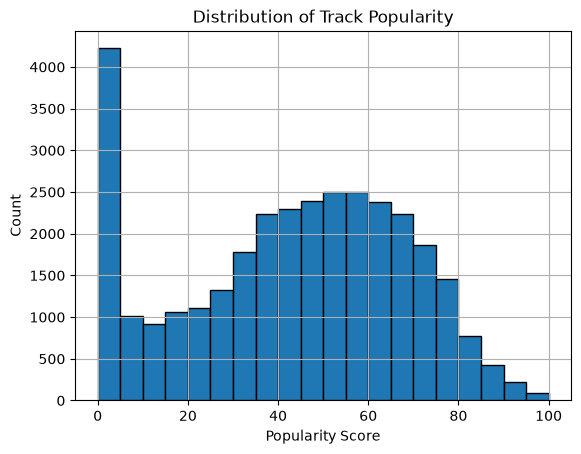

In [89]:
music['track_popularity'].hist(bins = 20, edgecolor = 'black') 
plt.title('Distribution of Track Popularity')
plt.xlabel('Popularity Score')
plt.ylabel('Count')
plt.show()

**Plotting and checking on the data we are gonna use to predict the track_popularity, danceability, energy, loudness, acousticness, instrumentalness, valence, tempo.**


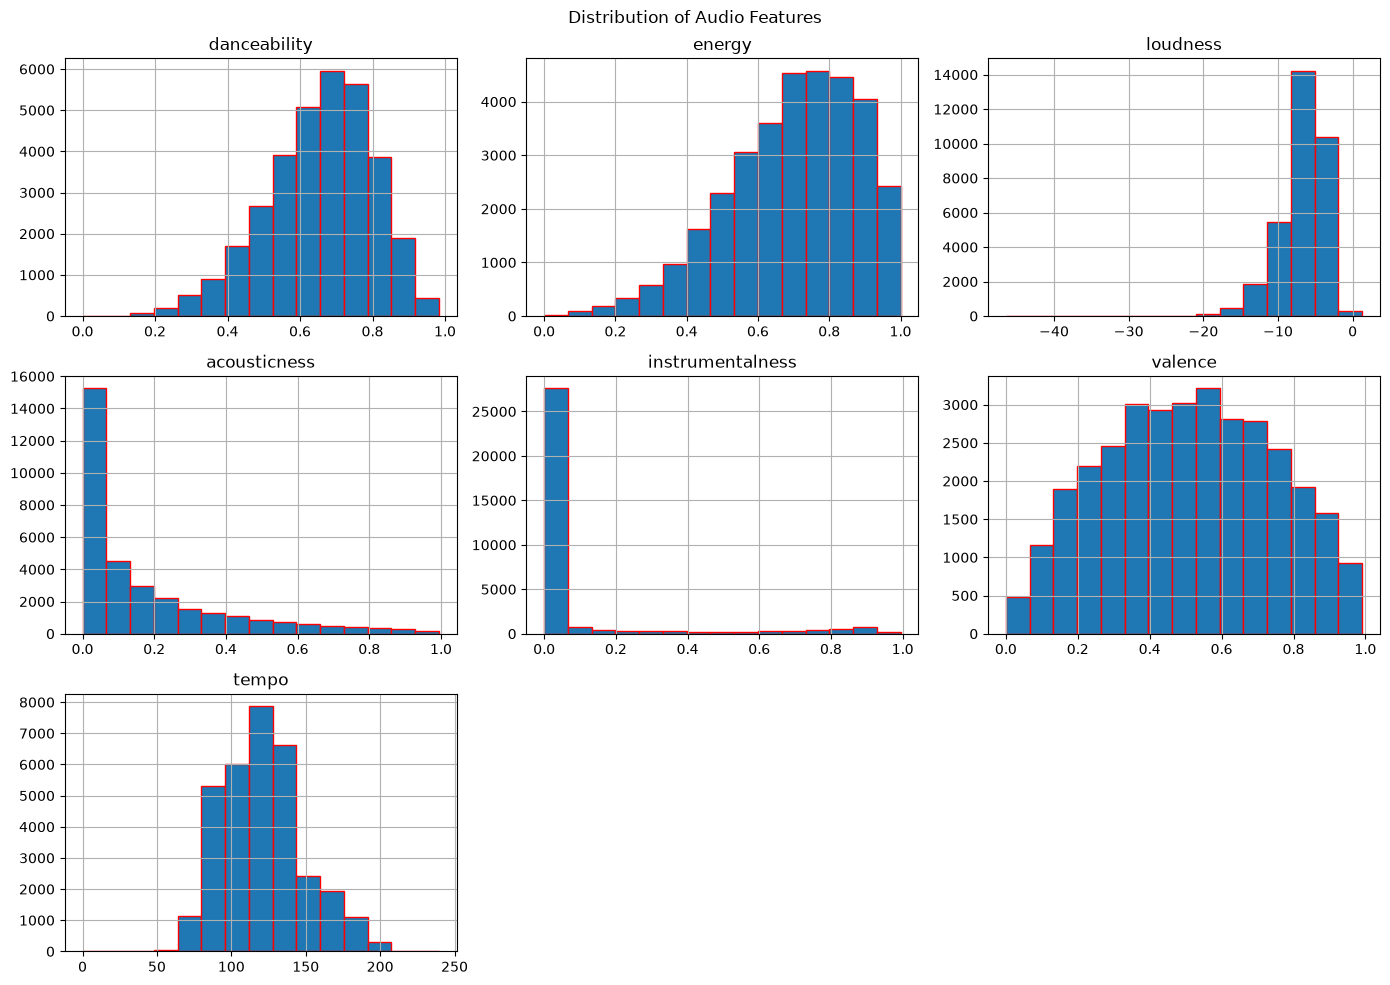

In [90]:
features = ['danceability', 'energy', 'loudness', 'acousticness', 'instrumentalness', 'valence', 'tempo']

music[features].hist(bins = 15, figsize = (14,10), edgecolor = 'red')
plt.suptitle('Distribution of Audio Features')
plt.tight_layout()
plt.show()


_`Danceability`, `Energy`, `Loudness` - left skewed_ \
*`Acousticness`, `Instrumentalness` - Right skewed* \
_`Variance` and `Tempo` are normal with equal distribution_

**`Instrumentalness` is merely usefull since everything lies on 0(mostly) so it has no data to tell if its all constant**

## Data Summary

**Dataset:** Spotify Songs — TidyTuesday (2020)  
**Source:** Spotify Web API via R4DS TidyTuesday Project  

- **Size:** 32,833 tracks × 23 columns (after cleaning: 32,828 rows, 5 null rows dropped)
- **Column types:** 10 string (metadata), 4 integer, 9 float (audio features)
- **No duplicate rows** detected
- **Target variable:** `track_popularity` — a continuous score from 0–100 assigned by Spotify based on total and recency of streams
- **Target distribution:** Slight left skew; majority of tracks score between 40–80, reflecting that this dataset is playlist-sourced (already somewhat popular tracks)
- **Predictor features used:** `danceability`, `energy`, `loudness`, `acousticness`, `instrumentalness`, `valence`, `tempo`
- **Notable observations:**
  - `acousticness` and `instrumentalness` are heavily right-skewed — most songs are non-acoustic with vocals
  - `instrumentalness` is near-zero for the vast majority of tracks — low predictive value expected
  - `loudness` ranges from −46 to 0 dB, reflecting standard audio normalisation

## Objective of the Analysis

This analysis aims to predict a song's popularity score using measurable audio 
features such as danceability, energy, loudness, acousticness, instrumentalness, 
valence, and tempo. By identifying which audio characteristics drive popularity, 
this model provides actionable insight for music producers and artists looking to 
understand what makes a song resonate with listeners. The findings can also help 
streaming platforms and record labels prioritise tracks with the highest potential 
for mainstream success.

In [91]:
new_features = ['danceability', 'energy', 'loudness', 'acousticness', 
            'instrumentalness', 'valence', 'tempo', 'track_popularity']

music_new = music[new_features].copy()
music_new.shape

(32828, 8)

In [92]:
music_new = music_new[music_new['track_popularity'] > 0]

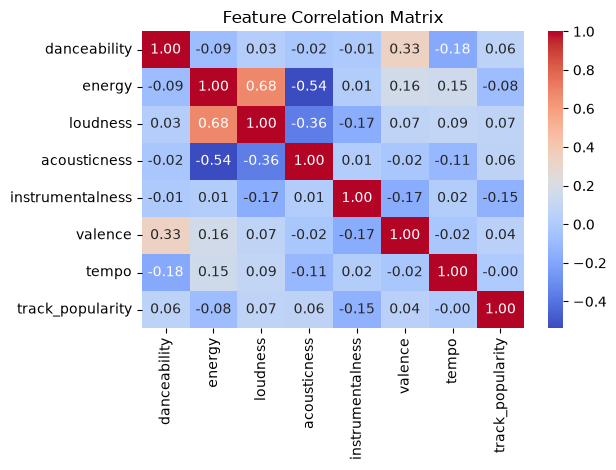

In [93]:
corr = music_new.corr()
sns.heatmap(corr, annot = True, fmt = '.2f', cmap = 'coolwarm')
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

In [94]:
#Here we see that energy and loudness are quite correlated at 0.68. So we drop one of them. Loudness for now
music_new = music_new.drop(columns=['loudness'])

In [113]:
x = music_new[['danceability']]
y = music_new['track_popularity']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

In [114]:
LR = LinearRegression()
LR.fit(x_train, y_train)
y_pred = LR.predict(x_test)

In [115]:
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print(f"R²: {r2:.4f}")
print(f"MSE: {mse:.4f}")

R²: 0.0036
MSE: 497.0233


In [117]:
X_multi = music_new[['danceability', 'energy', 'acousticness', 'instrumentalness', 'valence', 'tempo']]
x_train, x_test, y_train, y_test = train_test_split(X_multi, y, test_size = 0.2, random_state = 42)

In [121]:
LR2 = LinearRegression()
LR2.fit(x_train, y_train)
Y_Pred = LR2.predict(x_test)

In [125]:
r2 = r2_score(y_test, Y_Pred)
mse = mean_squared_error(y_test, Y_Pred)

print(f"R²: {r2:.4f}")
print(f"MSE: {mse:.4f}")

R²: 0.0289
MSE: 484.3761


In [139]:
R = Ridge(alpha = 0.1)
L = Lasso (alpha = 0.1)
R.fit(x_train, y_train)
L.fit(x_train, y_train)
RY_pred = R.predict(x_test)
LY_pred = L.predict(x_test)

In [140]:
r2 = r2_score(y_test, RY_pred)
mse = mean_squared_error(y_test, RY_pred)
r2l = r2_score(y_test, LY_pred)
msel = mean_squared_error(y_test, LY_pred)

print(f"R²: {r2:.4f}")
print(f"MSE: {mse:.4f}")

print(f"R²: {r2l:.4f}")
print(f"MSE: {msel:.4f}")

R²: 0.0289
MSE: 484.3758
R²: 0.0280
MSE: 484.8242


## Model Comparison

| Model | R² | MSE |
|---|---|---|
| Simple LR (danceability only) | 0.0036 | 497.02 |
| Multiple LR (all features) | 0.0289 | 484.38 |
| Ridge Regression (α=0.1) | 0.0289 | 484.38 |
| Lasso Regression (α=0.1) | 0.0280 | 484.82 |

**Best model: Multiple Linear Regression / Ridge** — identical performance, 
Ridge preferred as it handles multicollinearity between energy and acousticness.